# Detección de correos de phishing con aprendizaje automático y PLN
Curso: Aprendizaje Estadístico - NRC 4995 - Docente: Hernan Sagastegui Chigne - 2026-II

Integrantes: Eustaquio Ávila, Joel Antony - Marquez Rodriguez, Franco Guillermo - Velásquez Revilla, Favio Adriano

El data-set se descarga solo desde Kaggle (subhajournal/phishingemails). Si la descarga falla, el Colab pide subir `Phishing_Email.csv` o el `.zip`.

## Librerías

In [1]:
import re, os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import lru_cache
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

SEMILLA = 42   # semilla fija para que los resultados salgan iguales cada vez

# III. Planteamiento del Data-Set, Pre-Procesamiento y Normalización

## 3.1 Medidas, Datos y Características (Features)
Se usa el archivo del panel de Colab si ya está. Si no, se descarga desde Kaggle, y si eso falla, se pide subirlo.

In [2]:
import glob

# 1) Si el archivo ya está en el panel de Colab, se usa ese
if os.path.exists("Phishing_Email.csv"):
    archivo = "Phishing_Email.csv"
elif os.path.exists("Phishing_Email.zip"):
    zipfile.ZipFile("Phishing_Email.zip").extractall()
    archivo = "Phishing_Email.csv"
else:
    # 2) Si no está, se descarga directo desde Kaggle
    try:
        import kagglehub
        carpeta = kagglehub.dataset_download("subhajournal/phishingemails")
        archivo = glob.glob(os.path.join(carpeta, "**", "*.csv"), recursive=True)[0]
        print("Data-set descargado desde Kaggle")
    except Exception as error:
        # 3) Si Kaggle falla, se pide subir el archivo
        print("No se pudo descargar desde Kaggle:", error)
        print("Sube el archivo Phishing_Email.csv o el .zip:")
        from google.colab import files
        archivo = list(files.upload().keys())[0]
        if archivo.endswith(".zip"):
            zipfile.ZipFile(archivo).extractall()
            archivo = "Phishing_Email.csv"

df = pd.read_csv(archivo)
print("Filas y columnas:", df.shape)
df.head()

Using Colab cache for faster access to the 'phishingemails' dataset.
Data-set descargado desde Kaggle
Filas y columnas: (18650, 3)


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [3]:
print("Columnas:", df.columns.tolist())
print("\nValores nulos por columna:")
print(df.isna().sum())
print("\nCorreos por clase:")
print(df["Email Type"].value_counts())

Columnas: ['Unnamed: 0', 'Email Text', 'Email Type']

Valores nulos por columna:
Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

Correos por clase:
Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64


## 3.2 Normalización y Filtrado de Datos

### Limpieza de registros
Se quita la columna de índice, los textos nulos, los vacíos y los duplicados.

In [4]:
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={"Email Text": "texto", "Email Type": "clase"})

print("Data-set original:", len(df))
df = df.dropna(subset=["texto"])
print("Sin textos nulos: ", len(df))
df = df[df["texto"].str.strip() != ""]
print("Sin textos vacíos:", len(df))
df = df.drop_duplicates(subset="texto")
print("Sin duplicados:   ", len(df))

df["texto"] = df["texto"].str.slice(0, 20000)                  # recortar textos demasiado largos
df = df.reset_index(drop=True)
df["label"] = (df["clase"] == "Phishing Email").astype(int)     # 1 = phishing, 0 = legítimo

print("\nPorcentaje por clase:")
print((df["clase"].value_counts(normalize=True) * 100).round(1))

Data-set original: 18650
Sin textos nulos:  18634
Sin textos vacíos: 18631
Sin duplicados:    17536

Porcentaje por clase:
clase
Safe Email        62.6
Phishing Email    37.4
Name: proportion, dtype: float64


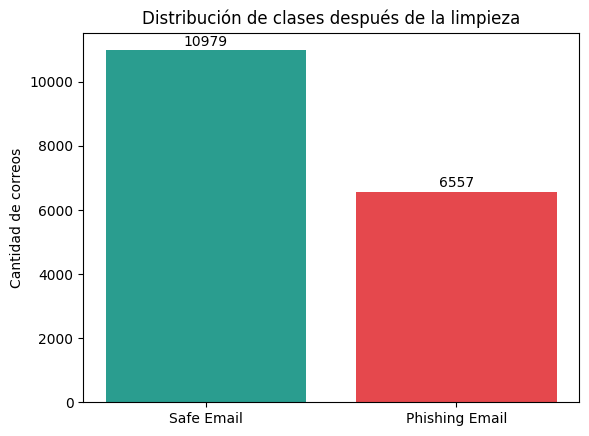

In [5]:
conteo = df["clase"].value_counts()
plt.bar(["Safe Email", "Phishing Email"], conteo.values, color=["#2A9D8F", "#E5484D"])
for i, v in enumerate(conteo.values):
    plt.text(i, v + 150, str(v), ha="center")
plt.title("Distribución de clases después de la limpieza")
plt.ylabel("Cantidad de correos")
plt.show()

### Características estructurales
Se calculan 6 medidas del texto de cada correo.

In [6]:
URGENCIA = ["urgent", "verify", "account", "password", "suspend", "confirm",
            "immediately", "bank", "security", "login", "click"]
patron_url = re.compile(r"http\S+|www\.\S+", re.I)
patron_urg = re.compile(r"\b(" + "|".join(URGENCIA) + r")\b", re.I)

def prop_mayus(t):
    letras = sum(c.isalpha() for c in t)
    if letras == 0:
        return 0.0
    return sum(c.isupper() for c in t) / letras

def estructurales(t):
    return {"n_urls": len(patron_url.findall(t)),      # enlaces
            "n_caracteres": len(t),                    # largo del correo
            "n_palabras": len(t.split()),              # cantidad de palabras
            "prop_mayus": prop_mayus(t),               # proporción de mayúsculas
            "n_exclam": t.count("!"),                  # signos de exclamación
            "n_urgencia": len(patron_urg.findall(t))}  # palabras de urgencia

COLS = ["n_urls", "n_caracteres", "n_palabras", "prop_mayus", "n_exclam", "n_urgencia"]
df[COLS] = pd.DataFrame(df["texto"].apply(estructurales).tolist())

promedios = df.groupby("clase")[COLS].mean().round(3)
promedios

,n_urls,n_caracteres,n_palabras,prop_mayus,n_exclam,n_urgencia
clase,,,,,,
Phishing Email,0.292,1641.607,311.555,0.027,3.385,1.081
Safe Email,0.771,1848.656,350.052,0.022,0.638,0.352


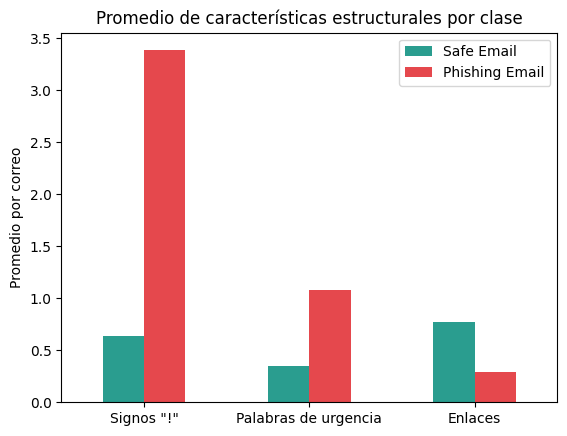

In [7]:
graf = promedios[["n_exclam", "n_urgencia", "n_urls"]].T[["Safe Email", "Phishing Email"]]
graf.index = ['Signos "!"', "Palabras de urgencia", "Enlaces"]
graf.plot(kind="bar", color=["#2A9D8F", "#E5484D"], rot=0)
plt.legend(title="")
plt.title("Promedio de características estructurales por clase")
plt.ylabel("Promedio por correo")
plt.show()

### Normalización del texto
Pasos: minúsculas, quitar HTML, enlaces y correos por etiquetas, quitar números y signos, quitar stopwords y stemming.

In [8]:
stemmer = PorterStemmer()

@lru_cache(maxsize=None)
def raiz(palabra):              # guarda las raíces ya calculadas para ir más rápido
    return stemmer.stem(palabra)

def limpiar_texto(s):
    s = s.lower()                                   # 1. minúsculas
    s = re.sub(r"<[^>]+>", " ", s)                  # 2. quitar HTML
    s = re.sub(r"http\S+|www\.\S+", " url ", s)    # 3. enlaces -> "url"
    s = re.sub(r"\S+@\S+", " email ", s)            # 4. correos -> "email"
    s = re.sub(r"[^a-z\s]", " ", s)                 # 5. quitar números y signos
    palabras = [p for p in s.split() if p not in ENGLISH_STOP_WORDS and len(p) > 2]   # 6. stopwords
    return " ".join(raiz(p) for p in palabras)      # 7. stemming

df["texto_limpio"] = df["texto"].apply(limpiar_texto)
print("ANTES:  ", df["texto"][1][:200])
print("DESPUÉS:", df["texto_limpio"][1][:200])

ANTES:   the other side of * galicismos * * galicismo * is a spanish term which names the improper introduction of french words which are spanish sounding and thus very deceptive to the ear . * galicismo * is 
DESPUÉS: galicismo galicismo spanish term name improp introduct french word spanish sound decept ear galicismo consid barbarismo term design opposit phenomenon unlaw word spanish origin crept french provid exa


### Archivo para WEKA
Se guardan las 6 características y la clase en formato ARFF para revisarlas en WEKA.

In [9]:
datos = df[COLS].round(4)
datos["clase"] = df["label"].map({0: "Safe", 1: "Phishing"})

with open("Phishing_Email_Detection_weka.arff", "w") as f:
    f.write("@relation phishing\n\n")
    for c in COLS:
        f.write(f"@attribute {c} numeric\n")
    f.write("@attribute clase {Safe,Phishing}\n\n@data\n")
    datos.to_csv(f, header=False, index=False)

print("Correos guardados en el ARFF:", len(datos))

Correos guardados en el ARFF: 17536


## 3.3 Data-Sets de entrenamiento, prueba y validación
70 % entrenamiento y 30 % prueba (estratificado). Dentro del entrenamiento se usa validación cruzada de 10 pliegues.

In [10]:
X = df[["texto_limpio"] + COLS]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y,
                                                    random_state=SEMILLA)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

print("Entrenamiento:", len(X_train), "correos -", round(y_train.mean() * 100, 1), "% phishing")
print("Prueba:       ", len(X_test), "correos -", round(y_test.mean() * 100, 1), "% phishing")
print("Validación cruzada: 10 pliegues de", len(X_train) // 10, "correos aprox.")

Entrenamiento: 12275 correos - 37.4 % phishing
Prueba:        5261 correos - 37.4 % phishing
Validación cruzada: 10 pliegues de 1227 correos aprox.


# IV. Aprendizaje

## 4.1 y 4.2 Modelo de regresión logística
El pipeline une el TF-IDF del texto, el escalado de las características y el modelo.

In [11]:
def crear_pipeline():
    preprocesador = ColumnTransformer([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=3,
                                  sublinear_tf=True), "texto_limpio"),
        ("estruct", Pipeline([("log", FunctionTransformer(np.log1p)),
                              ("minmax", MinMaxScaler())]), COLS),
    ])
    modelo = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced",
                                random_state=SEMILLA)
    return Pipeline([("preprocesador", preprocesador), ("modelo", modelo)])

def clasificar_correo(texto, pipeline):
    fila = pd.DataFrame([{"texto_limpio": limpiar_texto(texto), **estructurales(texto)}])
    p = pipeline.predict_proba(fila)[0, 1]          # probabilidad de phishing
    clase = "PHISHING" if p >= 0.5 else "LEGÍTIMO"
    return clase, round(float(p), 4)

# V. Comprobación

## 5.1 Entrenamiento del Modelo
### Validación cruzada de 10 pliegues (solo con el entrenamiento)

In [12]:
metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]
r = cross_validate(crear_pipeline(), X_train, y_train, cv=cv, scoring=metricas)

tabla_cv = pd.DataFrame({m: r["test_" + m] for m in metricas})
tabla_cv.index = [f"Pliegue {i}" for i in range(1, 11)]
tabla_cv.loc["Promedio"] = tabla_cv.mean()
tabla_cv.round(4)

,accuracy,precision,recall,f1,roc_auc
Pliegue 1,0.9756,0.9694,0.9651,0.9672,0.9960
Pliegue 2,0.9723,0.9590,0.9673,0.9631,0.9960
Pliegue 3,0.9699,0.9607,0.9586,0.9597,0.9959
Pliegue 4,0.9666,0.9485,0.9630,0.9557,0.9923
Pliegue 5,0.9707,0.9415,0.9826,0.9616,0.9948
Pliegue 6,0.9698,0.9587,0.9608,0.9597,0.9957
Pliegue 7,0.9772,0.9634,0.9760,0.9697,0.9958
Pliegue 8,0.9747,0.9612,0.9717,0.9664,0.9970
Pliegue 9,0.9788,0.9520,0.9935,0.9723,0.9965
Pliegue 10,0.9731,0.9651,0.9630,0.9640,0.9971


### Entrenamiento final y aplicación al Data-Set de prueba

In [13]:
import time

inicio = time.time()
modelo = crear_pipeline().fit(X_train, y_train)    # se entrena con los 12 275 correos
t_entrenamiento = time.time() - inicio

inicio = time.time()
pred = modelo.predict(X_test)                      # se aplica a los 5 261 correos de prueba
t_prueba = time.time() - inicio

print("Modelo entrenado y aplicado al conjunto de prueba")
print(f"Tiempo de entrenamiento: {t_entrenamiento:.1f} segundos")

Modelo entrenado y aplicado al conjunto de prueba
Tiempo de entrenamiento: 8.3 segundos


# VI. Evaluación

## 6.1 Métricas y Evaluación del Modelo

In [14]:
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
resultados = pd.DataFrame({
    "Métrica":   ["Accuracy", "Precision", "Recall", "F1-score", "Tasa de falsos positivos"],
    "Resultado": [accuracy_score(y_test, pred), precision_score(y_test, pred),
                  recall_score(y_test, pred), f1_score(y_test, pred), fp / (fp + tn)],
    "Meta":      ["> 0.90", "> 0.90", "> 0.90", "> 0.90", "< 0.05"],
})
resultados["¿Cumple?"] = ["Sí" if (v < 0.05 if i == 4 else v > 0.90) else "No"
                          for i, v in enumerate(resultados["Resultado"])]
resultados["Resultado"] = resultados["Resultado"].round(4)
resultados

,Métrica,Resultado,Meta,¿Cumple?
0,Accuracy,0.9766,> 0.90,Sí
1,Precision,0.9633,> 0.90,Sí
2,Recall,0.9746,> 0.90,Sí
3,F1-score,0.9689,> 0.90,Sí
4,Tasa de falsos positivos,0.0222,< 0.05,Sí


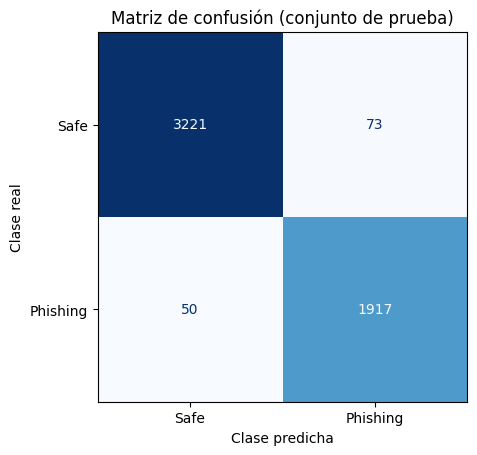

Verdaderos negativos: 3221 | Falsos positivos: 73 | Falsos negativos: 50 | Verdaderos positivos: 1917


In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Safe", "Phishing"],
                                        cmap="Blues", colorbar=False)
plt.title("Matriz de confusión (conjunto de prueba)")
plt.xlabel("Clase predicha"); plt.ylabel("Clase real")
plt.show()
print(f"Verdaderos negativos: {tn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdaderos positivos: {tp}")

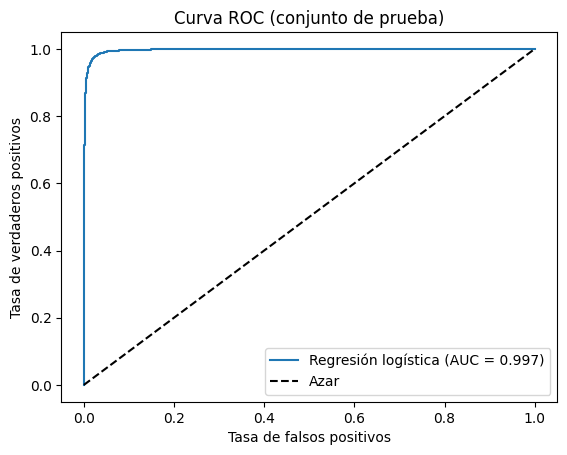

In [16]:
prob = modelo.predict_proba(X_test)[:, 1]          # probabilidad de phishing de cada correo
fpr, tpr, _ = roc_curve(y_test, prob)
auc = roc_auc_score(y_test, prob)
plt.plot(fpr, tpr, label=f"Regresión logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.title("Curva ROC (conjunto de prueba)")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

## 6.2 Evaluación de desempeño del Sistema de IA del Proyecto

### Tiempo de respuesta

In [17]:
inicio = time.time()
clasificar_correo("Please verify your account password now", modelo)
t_un_correo = time.time() - inicio

print(f"Entrenar el modelo (12 275 correos):     {t_entrenamiento:.1f} s")
print(f"Clasificar la prueba (5 261 correos):    {t_prueba:.2f} s")
print(f"Promedio por correo en la prueba:        {t_prueba / len(X_test) * 1000:.3f} ms")
print(f"Un correo nuevo con clasificar_correo:   {t_un_correo * 1000:.1f} ms")

Entrenar el modelo (12 275 correos):     8.3 s
Clasificar la prueba (5 261 correos):    1.17 s
Promedio por correo en la prueba:        0.223 ms
Un correo nuevo con clasificar_correo:   7.4 ms


### Prueba del sistema con correos nuevos
Correos escritos por nosotros, que no están en el data-set.

In [18]:
nuevos = [
    ("Hi John, attached is the report for tomorrow's meeting. Let me know if you have any questions. Thanks, Maria", "LEGÍTIMO"),
    ("Reminder: the team lunch was moved to Friday at 1 pm. See you there.", "LEGÍTIMO"),
    ("Hello professor, I am sending you the homework for chapter 4. Best regards, Franco", "LEGÍTIMO"),
    ("URGENT: Your account has been suspended! Verify your password immediately at http://paypa1-secure.com/login", "PHISHING"),
    ("Congratulations!!! You have won $1,000,000. Click here to claim your prize now: http://free-prize.win", "PHISHING"),
    ("Dear customer, we detected unusual activity in your bank account. Please login and confirm your details within 24 hours.", "PHISHING"),
]
filas = []
for texto, esperado in nuevos:
    clase, p = clasificar_correo(texto, modelo)
    filas.append({"Correo": texto[:60] + "...", "Esperado": esperado, "Predicho": clase,
                  "P(phishing)": p, "¿Acierta?": "Sí" if clase == esperado else "No"})
tabla_nuevos = pd.DataFrame(filas)
print("Aciertos:", (tabla_nuevos["¿Acierta?"] == "Sí").sum(), "de", len(tabla_nuevos))
tabla_nuevos

Aciertos: 5 de 6


,Correo,Esperado,Predicho,P(phishing),¿Acierta?
0,"Hi John, attached is the report for tomorrow's...",LEGÍTIMO,LEGÍTIMO,0.0180,Sí
1,Reminder: the team lunch was moved to Friday a...,LEGÍTIMO,LEGÍTIMO,0.1379,Sí
2,"Hello professor, I am sending you the homework...",LEGÍTIMO,PHISHING,0.7833,No
3,URGENT: Your account has been suspended! Verif...,PHISHING,PHISHING,0.7797,Sí
4,"Congratulations!!! You have won $1,000,000. Cl...",PHISHING,PHISHING,0.7846,Sí
5,"Dear customer, we detected unusual activity in...",PHISHING,PHISHING,0.8501,Sí


# VII. Despliegue (Deploy) del Sistema

## 7.1 Archivos para publicar en GitHub
Se guarda el modelo entrenado y se crean los archivos de la aplicación web:
- `modelo_phishing.joblib`: el pipeline entrenado (TF-IDF + características + regresión logística).
- `procesamiento.py`: las mismas funciones de limpieza del texto y características usadas en el Colab.
- `app.py`: la aplicación web hecha con Streamlit.
- `requirements.txt`: las librerías con las mismas versiones de este Colab.

In [19]:
import joblib, sys, sklearn, nltk

joblib.dump(modelo, "modelo_phishing.joblib")      # se guarda el modelo entrenado en 5.1

procesamiento = r"""import re
from functools import lru_cache
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

URGENCIA = ["urgent", "verify", "account", "password", "suspend", "confirm",
            "immediately", "bank", "security", "login", "click"]
patron_url = re.compile(r"http\S+|www\.\S+", re.I)
patron_urg = re.compile(r"\b(" + "|".join(URGENCIA) + r")\b", re.I)
stemmer = PorterStemmer()

@lru_cache(maxsize=None)
def raiz(palabra):
    return stemmer.stem(palabra)

def prop_mayus(t):
    letras = sum(c.isalpha() for c in t)
    if letras == 0:
        return 0.0
    return sum(c.isupper() for c in t) / letras

def estructurales(t):
    return {"n_urls": len(patron_url.findall(t)),
            "n_caracteres": len(t),
            "n_palabras": len(t.split()),
            "prop_mayus": prop_mayus(t),
            "n_exclam": t.count("!"),
            "n_urgencia": len(patron_urg.findall(t))}

def limpiar_texto(s):
    s = s.lower()
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"http\S+|www\.\S+", " url ", s)
    s = re.sub(r"\S+@\S+", " email ", s)
    s = re.sub(r"[^a-z\s]", " ", s)
    palabras = [p for p in s.split() if p not in ENGLISH_STOP_WORDS and len(p) > 2]
    return " ".join(raiz(p) for p in palabras)
"""

app = r"""import joblib
import pandas as pd
import streamlit as st
from procesamiento import limpiar_texto, estructurales

@st.cache_resource
def cargar_modelo():
    return joblib.load("modelo_phishing.joblib")

modelo = cargar_modelo()

st.title("Detector de correos de phishing")
st.write("Pega el texto de un correo en inglés y el sistema dirá si es phishing o legítimo.")

texto = st.text_area("Texto del correo", height=220)

if st.button("Analizar"):
    if texto.strip() == "":
        st.warning("Primero pega el texto de un correo.")
    else:
        fila = pd.DataFrame([{"texto_limpio": limpiar_texto(texto), **estructurales(texto)}])
        p = modelo.predict_proba(fila)[0, 1]
        if p >= 0.5:
            st.error(f"PHISHING - probabilidad: {p * 100:.1f} %")
        else:
            st.success(f"LEGÍTIMO - probabilidad de phishing: {p * 100:.1f} %")

st.caption("Aprendizaje Estadístico - UPAO 2026-II | Eustaquio Ávila, Marquez Rodriguez, Velásquez Revilla")
"""

requisitos = f"""streamlit
scikit-learn=={sklearn.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
nltk=={nltk.__version__}
joblib=={joblib.__version__}
"""

open("procesamiento.py", "w").write(procesamiento)
open("app.py", "w").write(app)
open("requirements.txt", "w").write(requisitos)

print("Archivos creados: modelo_phishing.joblib, procesamiento.py, app.py, requirements.txt")
print("\nrequirements.txt:\n" + requisitos)
print("Versión de Python de este Colab:", sys.version.split()[0])

Archivos creados: modelo_phishing.joblib, procesamiento.py, app.py, requirements.txt

requirements.txt:
streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
nltk==3.9.1
joblib==1.6.0

Versión de Python de este Colab: 3.13.18


### Prueba de los archivos generados
Se carga el modelo desde el archivo y se usan las funciones de `procesamiento.py`, igual que lo hará la app. Las probabilidades deben salir iguales a las del punto 6.2.

In [20]:
import importlib, procesamiento
importlib.reload(procesamiento)

modelo_cargado = joblib.load("modelo_phishing.joblib")
for texto, esperado in nuevos:
    fila = pd.DataFrame([{"texto_limpio": procesamiento.limpiar_texto(texto),
                          **procesamiento.estructurales(texto)}])
    p = modelo_cargado.predict_proba(fila)[0, 1]
    print(f"{esperado:9s} -> {round(float(p), 4)}")

LEGÍTIMO  -> 0.018
LEGÍTIMO  -> 0.1379
LEGÍTIMO  -> 0.7833
PHISHING  -> 0.7797
PHISHING  -> 0.7846
PHISHING  -> 0.8501


### Descargar los archivos
Se juntan los 4 archivos en un .zip para subirlos a GitHub.

In [21]:
import zipfile
with zipfile.ZipFile("despliegue_phishing.zip", "w") as z:
    for f in ["app.py", "procesamiento.py", "modelo_phishing.joblib", "requirements.txt"]:
        z.write(f)
print("Listo: despliegue_phishing.zip")

try:
    from google.colab import files
    files.download("despliegue_phishing.zip")
except ImportError:
    pass

Listo: despliegue_phishing.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7.2 Deploy de la App web
1. Subir a un repositorio público de GitHub los archivos del .zip, el notebook y un README con la documentación.
2. Entrar a share.streamlit.io con la cuenta de GitHub, elegir **Create app**, el repositorio, la rama `main` y el archivo `app.py`.
3. En **Advanced settings**, elegir la misma versión de Python que se mostró arriba.
4. Al terminar, Streamlit da el enlace público de la aplicación.